<a href="https://colab.research.google.com/github/2952342H/Battery-Analysis/blob/main/batch2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload all three Batch 2 files:
  0.2_001.xlsx
  0.2_002.xlsx
  0.2_003.xlsx


Saving 0.2_003.xlsx to 0.2_003.xlsx
Saving 0.2_002.xlsx to 0.2_002.xlsx
Saving 0.2_001.xlsx to 0.2_001.xlsx

Reading 0.2_001.xlsx...

Reading 0.2_002.xlsx...

Reading 0.2_003.xlsx...

Completed-cycle counts:
{'001': 0, '002': 0, '003': 6}
Cell 001: cycle 1, CC Chg, 1.9009 V, 57.13 h in this step
Cell 002: cycle 1, CC Chg, 3.7748 V, 57.09 h in this step
Cell 003: cycle 7, CC Chg, 3.8293 V, 0.96 h in this step


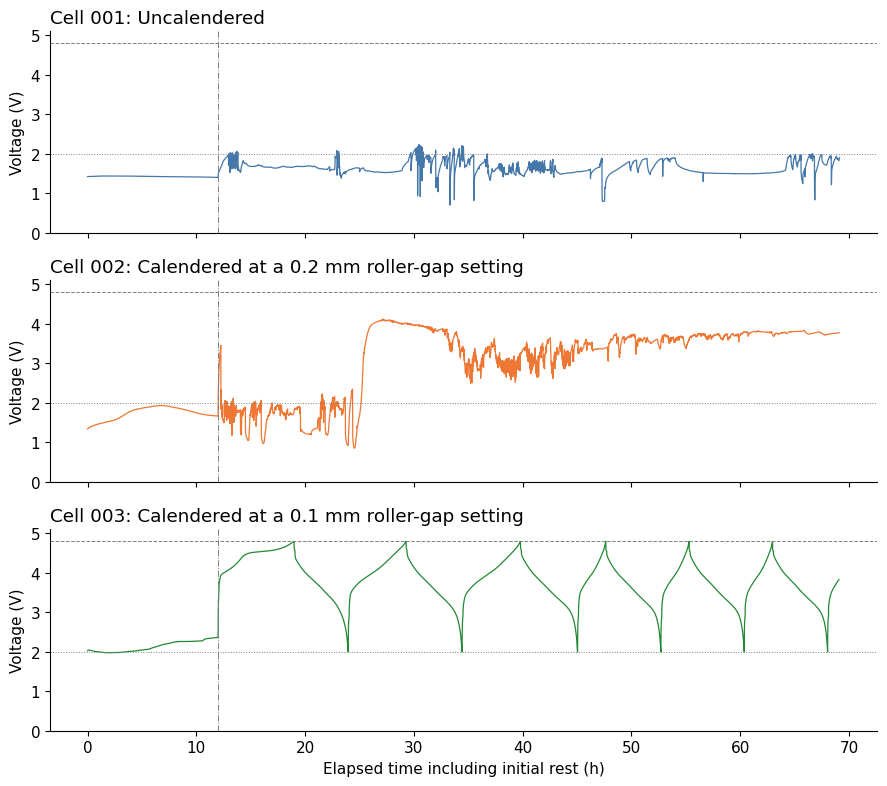

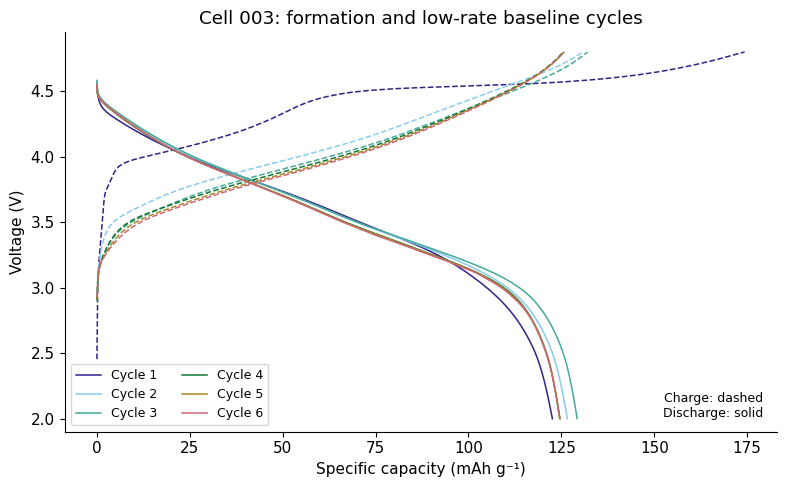

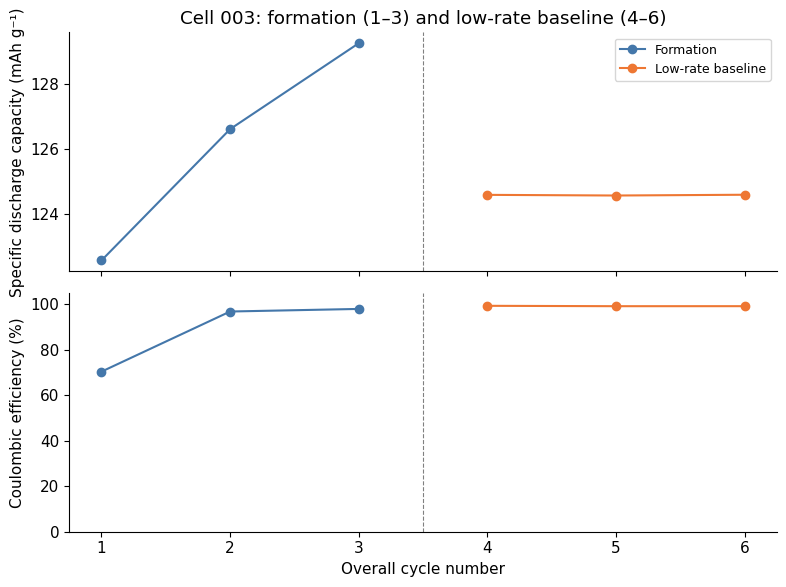


Analysis complete. Downloading results...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
"""
Batch 2 preliminary electrochemical analysis for Google Colab.

Required files:
    0.2_001.xlsx
    0.2_002.xlsx
    0.2_003.xlsx

All electrodes were prepared at a 0.2 mm coating gap.
Active material mass: 4.88 mg per electrode.

This script reads only the files selected in the current upload.
"""

import csv
import math
import shutil
import tempfile
import warnings
from collections import defaultdict
from datetime import datetime, timedelta
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
from google.colab import files
from openpyxl import load_workbook


# ============================================================
# Configuration
# ============================================================

CELLS = {
    "001": {
        "file": "0.2_001.xlsx",
        "condition": "Uncalendered",
        "thickness_um": 41,
        "mass_mg": 4.88,
        "color": "#4477AA",
    },
    "002": {
        "file": "0.2_002.xlsx",
        "condition": "Calendered at a 0.2 mm roller-gap setting",
        "thickness_um": 34,
        "mass_mg": 4.88,
        "color": "#EE7733",
    },
    "003": {
        "file": "0.2_003.xlsx",
        "condition": "Calendered at a 0.1 mm roller-gap setting",
        "thickness_um": 30,
        "mass_mg": 4.88,
        "color": "#228833",
    },
}

CHARGE_CUTOFF = 4.8
DISCHARGE_CUTOFF = 2.0

# Endpoint tolerance is an analysis criterion, not a safety setting.
VOLTAGE_TOLERANCE = 0.01

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.fontsize": 9,
})


# ============================================================
# Utilities
# ============================================================

def numeric(value):
    return (
        isinstance(value, (int, float))
        and not isinstance(value, bool)
        and math.isfinite(float(value))
    )


def number_or_none(value):
    return float(value) if numeric(value) else None


def hours(value):
    """Convert elapsed time to hours."""

    if isinstance(value, timedelta):
        return value.total_seconds() / 3600

    parts = str(value).strip().split(":")
    if len(parts) != 3:
        raise ValueError(f"Unsupported time format: {value!r}")

    return (
        float(parts[0])
        + float(parts[1]) / 60
        + float(parts[2]) / 3600
    )


def stage(cycle):
    boundaries = [
        (3, "Formation"),
        (6, "Low-rate baseline"),
        (9, "Rate test: 0.2C discharge"),
        (12, "Rate test: 0.5C discharge"),
        (15, "Rate test: 1C discharge"),
        (18, "Rate test: 2C discharge"),
        (21, "Capacity recovery"),
    ]
    for end, label in boundaries:
        if cycle <= end:
            return label
    return "0.5C cycling"


def write_csv(path, rows):
    if not rows:
        return
    with path.open("w", newline="", encoding="utf-8-sig") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def save_plot(fig, folder, name):
    fig.tight_layout()
    fig.savefig(
        folder / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    fig.savefig(
        folder / f"{name}.pdf",
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close(fig)


# ============================================================
# Fresh upload
# ============================================================

def upload_files():
    """Always request a new upload and read its returned bytes."""

    print("Upload all three Batch 2 files:")
    for config in CELLS.values():
        print(" ", config["file"])

    uploaded = files.upload()

    missing = [
        config["file"]
        for config in CELLS.values()
        if config["file"] not in uploaded
    ]

    if missing:
        raise ValueError(
            "Missing files in this upload: "
            + ", ".join(missing)
            + "\nSelect all three files with the exact filenames."
        )

    return uploaded


# ============================================================
# Mixed-table Neware reader
# ============================================================

def read_export(content, filename):
    """
    Read mixed-table exports.

    Numerical column A: cycle summary.
    Numerical column B: step summary.
    Numerical column C: individual record.
    """

    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Workbook contains no default style",
        )
        workbook = load_workbook(
            BytesIO(content),
            read_only=True,
            data_only=True,
        )

    try:
        if len(workbook.sheetnames) != 1:
            raise ValueError(
                f"{filename}: use the single-sheet mixed-table export."
            )

        sheet = workbook.active
        sheet.reset_dimensions()
        iterator = sheet.iter_rows(values_only=True)
        header = next(iterator, None)

        if not header or str(header[0]).strip() != "Cycle Index":
            raise ValueError(f"{filename}: unexpected worksheet header.")

        summaries, steps, records = [], [], []
        cycle = None
        current_step = None

        for original in iterator:
            row = list(original)
            row.extend([None] * max(0, 12 - len(row)))

            if numeric(row[0]):
                cycle = int(row[0])
                summaries.append({
                    "cycle": cycle,
                    "charge_mAh": number_or_none(row[1]),
                    "discharge_mAh": number_or_none(row[2]),
                })

            elif numeric(row[1]):
                if cycle is None:
                    raise ValueError(f"{filename}: missing cycle identifier.")

                current_step = {
                    "cycle": cycle,
                    "step_index": int(row[1]),
                    "step_type": str(row[3]).strip(),
                    "end_voltage_V": number_or_none(row[8]),
                }
                steps.append(current_step)

            elif numeric(row[2]) and current_step is not None:
                if not all(numeric(row[i]) for i in (5, 6, 7)):
                    raise ValueError(
                        f"{filename}: invalid record at DataPoint {row[2]}."
                    )

                timestamp = (
                    row[9].isoformat(sep=" ")
                    if isinstance(row[9], datetime)
                    else str(row[9])
                )

                records.append({
                    "cycle": cycle,
                    "step_index": current_step["step_index"],
                    "step_type": current_step["step_type"],
                    "data_point": int(row[2]),
                    "step_time_h": hours(row[3]),
                    "total_time_h": hours(row[4]),
                    "current_mA": float(row[5]),
                    "voltage_V": float(row[6]),
                    "capacity_mAh": float(row[7]),
                    "timestamp": timestamp,
                })

        if not records:
            raise ValueError(f"{filename}: no testing records found.")

        return {
            "summaries": summaries,
            "steps": steps,
            "records": records,
        }

    finally:
        workbook.close()


# ============================================================
# Completed-cycle validation
# ============================================================

def completed_cycles(parsed, mass_mg):
    """Check recorded and summary endpoints before calculating metrics."""

    records_by_type = defaultdict(list)
    steps_by_type = defaultdict(list)

    for record in parsed["records"]:
        records_by_type[
            (record["cycle"], record["step_type"])
        ].append(record)

    for step_record in parsed["steps"]:
        steps_by_type[
            (step_record["cycle"], step_record["step_type"])
        ].append(step_record)

    results, checks = [], []

    for summary in parsed["summaries"]:
        cycle = summary["cycle"]
        charge = records_by_type[(cycle, "CC Chg")]
        discharge = records_by_type[(cycle, "CC DChg")]
        charge_steps = steps_by_type[(cycle, "CC Chg")]
        discharge_steps = steps_by_type[(cycle, "CC DChg")]

        charge_end = charge[-1]["voltage_V"] if charge else None
        discharge_end = discharge[-1]["voltage_V"] if discharge else None

        charge_summary_end = (
            charge_steps[-1]["end_voltage_V"] if charge_steps else None
        )
        discharge_summary_end = (
            discharge_steps[-1]["end_voltage_V"]
            if discharge_steps else None
        )

        charge_ok = (
            charge_end is not None
            and charge_summary_end is not None
            and charge_end >= CHARGE_CUTOFF - VOLTAGE_TOLERANCE
            and charge_summary_end >= CHARGE_CUTOFF - VOLTAGE_TOLERANCE
        )

        discharge_ok = (
            discharge_end is not None
            and discharge_summary_end is not None
            and discharge_end <= DISCHARGE_CUTOFF + VOLTAGE_TOLERANCE
            and discharge_summary_end <= DISCHARGE_CUTOFF + VOLTAGE_TOLERANCE
        )

        qc = summary["charge_mAh"]
        qd = summary["discharge_mAh"]
        capacities_ok = (
            qc is not None and qd is not None and qc > 0 and qd > 0
        )
        include = charge_ok and discharge_ok and capacities_ok

        checks.append({
            "cycle": cycle,
            "stage": stage(cycle),
            "charge_endpoint_V": charge_end,
            "discharge_endpoint_V": discharge_end,
            "charge_endpoint_confirmed": charge_ok,
            "discharge_endpoint_confirmed": discharge_ok,
            "included": include,
        })

        if include:
            results.append({
                "cycle": cycle,
                "stage": stage(cycle),
                "charge_mAh": qc,
                "discharge_mAh": qd,
                "specific_charge_mAh_g": qc / (mass_mg / 1000),
                "specific_discharge_mAh_g": qd / (mass_mg / 1000),
                "CE_percent": 100 * qd / qc,
            })

    return results, checks


# ============================================================
# Figures
# ============================================================

def voltage_time_figure(data, folder):
    fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)

    for ax, (cell, config) in zip(axes, CELLS.items()):
        records = data[cell]["records"]
        ax.plot(
            [r["total_time_h"] for r in records],
            [r["voltage_V"] for r in records],
            color=config["color"],
            linewidth=0.9,
        )
        ax.axhline(4.8, color="grey", linestyle="--", linewidth=0.7)
        ax.axhline(2.0, color="grey", linestyle=":", linewidth=0.7)
        ax.axvline(12, color="grey", linestyle="-.", linewidth=0.7)
        ax.set_title(f"Cell {cell}: {config['condition']}", loc="left")
        ax.set_ylabel("Voltage (V)")
        ax.set_ylim(0, 5.1)

    axes[-1].set_xlabel("Elapsed time including initial rest (h)")
    save_plot(fig, folder, "Figure_4_2_1_Voltage_Time")


def voltage_capacity_figure(data, folder):
    initial = [
        r for r in data["003"]["completed"] if r["cycle"] <= 6
    ]
    if not initial:
        print("Cell 003 has no completed initial cycles to plot.")
        return

    mass_g = CELLS["003"]["mass_mg"] / 1000
    colors = [
        "#332288", "#88CCEE", "#44AA99",
        "#117733", "#AA8822", "#CC6677",
    ]
    fig, ax = plt.subplots(figsize=(8, 5))

    for position, result in enumerate(initial):
        cycle = result["cycle"]

        for kind, style in [("CC Chg", "--"), ("CC DChg", "-")]:
            segments = defaultdict(list)
            for record in data["003"]["records"]:
                if record["cycle"] == cycle and record["step_type"] == kind:
                    segments[record["step_index"]].append(record)

            for index, segment in enumerate(segments.values()):
                ax.plot(
                    [r["capacity_mAh"] / mass_g for r in segment],
                    [r["voltage_V"] for r in segment],
                    linestyle=style,
                    color=colors[position % len(colors)],
                    linewidth=1.1,
                    label=(
                        f"Cycle {cycle}"
                        if kind == "CC DChg" and index == 0 else None
                    ),
                )

    ax.set_xlabel("Specific capacity (mAh g⁻¹)")
    ax.set_ylabel("Voltage (V)")
    ax.set_ylim(1.9, 4.95)
    ax.set_title("Cell 003: formation and low-rate baseline cycles")
    ax.legend(ncol=2, loc="lower left")
    ax.text(
        0.98, 0.03,
        "Charge: dashed\nDischarge: solid",
        transform=ax.transAxes,
        ha="right", va="bottom", fontsize=9,
    )
    save_plot(fig, folder, "Figure_4_2_1_Cell003_Curves")


def capacity_efficiency_figure(data, folder):
    initial = [
        r for r in data["003"]["completed"] if r["cycle"] <= 6
    ]
    if not initial:
        return

    fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

    for label, color in [
        ("Formation", "#4477AA"),
        ("Low-rate baseline", "#EE7733"),
    ]:
        selected = [r for r in initial if r["stage"] == label]
        if not selected:
            continue

        cycles = [r["cycle"] for r in selected]
        axes[0].plot(
            cycles,
            [r["specific_discharge_mAh_g"] for r in selected],
            "o-", color=color, label=label,
        )
        axes[1].plot(
            cycles,
            [r["CE_percent"] for r in selected],
            "o-", color=color,
        )

    for ax in axes:
        ax.axvline(3.5, color="grey", linestyle="--", linewidth=0.8)

    axes[0].set_ylabel("Specific discharge capacity (mAh g⁻¹)")
    axes[0].set_title(
        "Cell 003: formation (1–3) and low-rate baseline (4–6)"
    )
    axes[0].legend()
    axes[1].set_ylabel("Coulombic efficiency (%)")
    axes[1].set_xlabel("Overall cycle number")
    axes[1].set_xticks(range(1, 7))
    axes[1].set_ylim(0, 105)

    save_plot(fig, folder, "Figure_4_2_3_Cell003_Capacity_CE")


# ============================================================
# Run analysis
# ============================================================

def main():
    uploaded = upload_files()

    # Create a separate output folder for each execution.
    folder = Path(tempfile.mkdtemp(prefix="Batch2_Results_"))

    data = {}
    status_rows = []
    cycle_rows = []
    check_rows = []

    for cell, config in CELLS.items():
        filename = config["file"]
        print(f"\nReading {filename}...")

        parsed = read_export(uploaded[filename], filename)
        results, checks = completed_cycles(parsed, config["mass_mg"])
        parsed["completed"] = results
        data[cell] = parsed
        latest = parsed["records"][-1]

        status_rows.append({
            "cell": cell,
            "source_file": filename,
            "condition": config["condition"],
            "coating_gap_mm": 0.2,
            "coating_thickness_um": config["thickness_um"],
            "active_mass_mg": config["mass_mg"],
            "completed_cycles": len(results),
            "latest_cycle": latest["cycle"],
            "latest_step": latest["step_type"],
            "latest_voltage_V": latest["voltage_V"],
            "latest_current_mA": latest["current_mA"],
            "latest_total_time_h": latest["total_time_h"],
            "latest_step_time_h": latest["step_time_h"],
            "latest_step_capacity_mAh": latest["capacity_mAh"],
            "export_end_timestamp": latest["timestamp"],
        })

        cycle_rows.extend({"cell": cell, **r} for r in results)
        check_rows.extend({"cell": cell, **r} for r in checks)

        write_csv(
            folder / f"Cell_{cell}_Parsed_Records.csv",
            parsed["records"],
        )

    write_csv(folder / "Cell_Status.csv", status_rows)
    write_csv(folder / "Completed_Cycles.csv", cycle_rows)
    write_csv(folder / "Cycle_Validation.csv", check_rows)

    print("\nCompleted-cycle counts:")
    print({cell: len(parsed["completed"]) for cell, parsed in data.items()})

    for row in status_rows:
        print(
            f"Cell {row['cell']}: cycle {row['latest_cycle']}, "
            f"{row['latest_step']}, {row['latest_voltage_V']:.4f} V, "
            f"{row['latest_step_time_h']:.2f} h in this step"
        )

    voltage_time_figure(data, folder)
    voltage_capacity_figure(data, folder)
    capacity_efficiency_figure(data, folder)

    notes = (
        "Only files selected in the current upload were analysed.\n"
        "Active material mass: 4.88 mg per electrode.\n"
        "Voltage-time curves include initial rest.\n"
        "No smoothing was applied.\n"
        "Incomplete cycles were excluded from completed-cycle metrics.\n"
        "Cell 003 capacity figures include completed cycles 1-6 only.\n"
        "Rate retention and long-term cycling retention were not calculated.\n"
        "Endpoint validation does not establish that a cell is fault-free.\n"
    )
    (folder / "Analysis_Notes.txt").write_text(notes, encoding="utf-8")

    archive = shutil.make_archive(str(folder), "zip", root_dir=folder)
    print("\nAnalysis complete. Downloading results...")
    files.download(archive)


# Notebook kernel arguments are not parsed.
main()